# Nowe nagrania klienta · 30.09.2026
Otwórz repo w VS Code, kernel **.venv / Ping Lab**, kliknij **Run All**. Wszystko działa lokalnie. AST korzysta z wag `models/ast` i cache; pierwsze przeliczenie bez cache trwa dłużej. Na tym komputerze wagi są już pobrane.

Ten notebook jest aktualnym wejściem do analizy **wszystkich czterech dostaw**. Starsze 02–04 zachowują wyniki z 29.09. ID płytek w tej rundzie są założeniami do potwierdzenia.

In [17]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/pinglab').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Otwórz notebook wewnątrz repo ceramic-ping-lab.')
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT/'scripts'))
import pandas as pd
from IPython.display import display, Image, Markdown
from pinglab import clientupdate as update, clientstudy
from build_client_update import build_report, INTRO, METHOD, QUESTIONS
OUT = ROOT/update.OUT_REL
%matplotlib inline
records, events, features = update.prepare(ROOT)
display(Markdown(INTRO))

E01: 11/12 kandydatów · Mic Enhancements Off/OK no enhacements off.wav
E02: 11/13 kandydatów · Mic Enhancements Off/Ok no enhacements off angle.wav
E03: 0/0 kandydatów · Mic Enhancements Off/factory noise- Enhancements off.wav
L01: 15/15 kandydatów · BAD/BAD2/BAD lab test angle single point.wav
L02: 25/25 kandydatów · BAD/BAD2/NOK LAB TEST 2.wav
L03: 25/25 kandydatów · BAD/BAD2/NOK LAB TEST 3.wav
L04: 14/14 kandydatów · BAD/BAD2/NOK LAB TEST.wav
L05: 25/25 kandydatów · BAD/BAD2/NOK LAB Test angle.wav
L06: 14/14 kandydatów · BAD/BAD2/NOK LAB test angle 2.wav
L07: 22/22 kandydatów · BAD/BAD2/NOK lab test angle 3.wav
L08: 22/22 kandydatów · OK/OK LAB TEST 2.wav
L09: 17/17 kandydatów · OK/OK LAB TEST 3.wav
L10: 16/16 kandydatów · OK/OK LAB TEST ANGLE 2.wav
L11: 8/8 kandydatów · OK/OK LAB TEST ANGLE.wav
L12: 12/12 kandydatów · OK/OK LAB TEST angle 3 one point.wav
L13: 21/21 kandydatów · OK/OK lab test.wav


Nowe dane są wyraźnie inne. Folder **Mic Enhancements Off** wygląda lepiej pod kątem zachowania tła: 0/3 plików ma ciąg dokładnych zer dłuższy niż 100 ms. W **LAB TEST** takie odcinki występują w 13/13 plików, trwają do około 2,4 s; mediana udziału zer w pliku to około 56%. Sam sygnał nie rozstrzyga, czy to bramka, odszumianie, edycja czy przerwy toru.

Uderzenia są teraz rzadsze: typowy odstęp wynosi około 2,1–2,2 s wobec około 0,28 s wcześniej. To daje miejsce na ogon dźwięku, ale cyfrowe wyciszanie nadal ogranicza badanie zaniku. Nie mamy jeszcze dowodu, że dłuższy ogon poprawi klasyfikację.

**Najważniejszy wynik:** model MFCC + regresja uczony tylko na wcześniejszych danych trafia 12/13 plików LAB, lecz odrzuca oba nowe OK z Enhancements Off. Potrzebujemy NOK nagranego w tych samych warunkach z wyłączonymi ulepszeniami. Nie należy cofać tej zmiany po to, żeby poprawić wynik starego modelu.

## 1. Co przyjechało i jak interpretujemy nazwy
Końcówki 2/3 traktujemy jako numery nagrań, nie dowód nowej płytki. „Mic Enhancements Off” jest deklaracją z nazwy. „LAB TEST” nie potwierdza wyłączenia ulepszeń. „single point” nie rozstrzyga rodzaju podparcia.

In [18]:
new = records[records.recording_id.str.startswith(('E', 'L'))]
display(new[['recording_id','filename','group','label','processing','duration_s','n_accepted']])
display(Markdown(QUESTIONS))

,recording_id,filename,group,label,processing,duration_s,n_accepted
45,E01,Mic Enhancements Off/OK no enhacements off.wav,OK_ENH_OFF,0,off_by_folder_name,30.14,11
46,E02,Mic Enhancements Off/Ok no enhacements off ang...,OK_ENH_OFF,0,off_by_folder_name,25.10,11
47,E03,Mic Enhancements Off/factory noise- Enhancemen...,BACKGROUND_NEW,-1,off_by_folder_name,34.41,0
48,L01,BAD/BAD2/BAD lab test angle single point.wav,NOK_LAB_BAD2,1,unknown_LAB_TEST,36.52,15
49,L02,BAD/BAD2/NOK LAB TEST 2.wav,NOK_LAB_BAD2,1,unknown_LAB_TEST,58.94,25
50,L03,BAD/BAD2/NOK LAB TEST 3.wav,NOK_LAB_BAD2,1,unknown_LAB_TEST,56.62,25
51,L04,BAD/BAD2/NOK LAB TEST.wav,NOK_LAB_BAD2,1,unknown_LAB_TEST,29.78,14
52,L05,BAD/BAD2/NOK LAB Test angle.wav,NOK_LAB_BAD2,1,unknown_LAB_TEST,55.34,25
53,L06,BAD/BAD2/NOK LAB test angle 2.wav,NOK_LAB_BAD2,1,unknown_LAB_TEST,28.33,14
54,L07,BAD/BAD2/NOK lab test angle 3.wav,NOK_LAB_BAD2,1,unknown_LAB_TEST,42.68,22


1. Czy nowe `BAD/BAD2` to ta sama fizyczna płytka co wcześniejsze `Bad_2`, czy nowa pęknięta sztuka? Prosimy o krótkie przypisanie: folder → ID płytki → pęknięcie / wyszczerbienie / OK.
2. Czy pliki w `LAB TEST` powstały przed czy po wyłączeniu ulepszeń? Czy `LAB` oznacza inne pomieszczenie, aplikację lub mikrofon? W każdym z tych 13 plików nadal są długie odcinki dokładnego zera.
3. Czy `OK` z LAB i `OK` z Mic Enhancements Off to ta sama płytka? Która z poprzednich OK? Czy końcówki 2 i 3 oznaczają powtórzenie nagrania, a nie nową sztukę?
4. Co oznacza `angle` (kąt mikrofonu czy uderzenia) oraz `single point / one point` (miejsce uderzania czy podparcie)? W tych ZIP-ach nie znaleźliśmy nazw `no freq` ani `no frequency`.

## 2. Jakość: nowe kontra poprzednie
Dokładne zera liczymy w oryginalnym kanale, przed usuwaniem DC i normalizacją. Pojedyncze zerowe próbki PCM są normalne; sprawdzamy długie ciągi. −240 dBFS w tabeli oznacza cyfrowe zero; wykres ucina skalę dla czytelności.

,batch,files,seconds,files_zero100ms,median_zero_fraction,median_floor_dbfs,median_peak_dbfs,max_clipping,accepted,median_gap_s
0,1-batch-ping,24,744.562,7,0.000,-77.619,-10.443,0.0,2308,0.260
1,2-batch-ok,21,439.930,10,0.058,-77.876,-11.601,0.0,1305,0.293
2,3-batch-enhancements-off,3,89.650,0,0.001,-41.841,-7.909,0.0,22,2.245
3,4-batch-lab-test,13,526.350,13,0.555,-240.000,-6.973,0.0,236,2.110


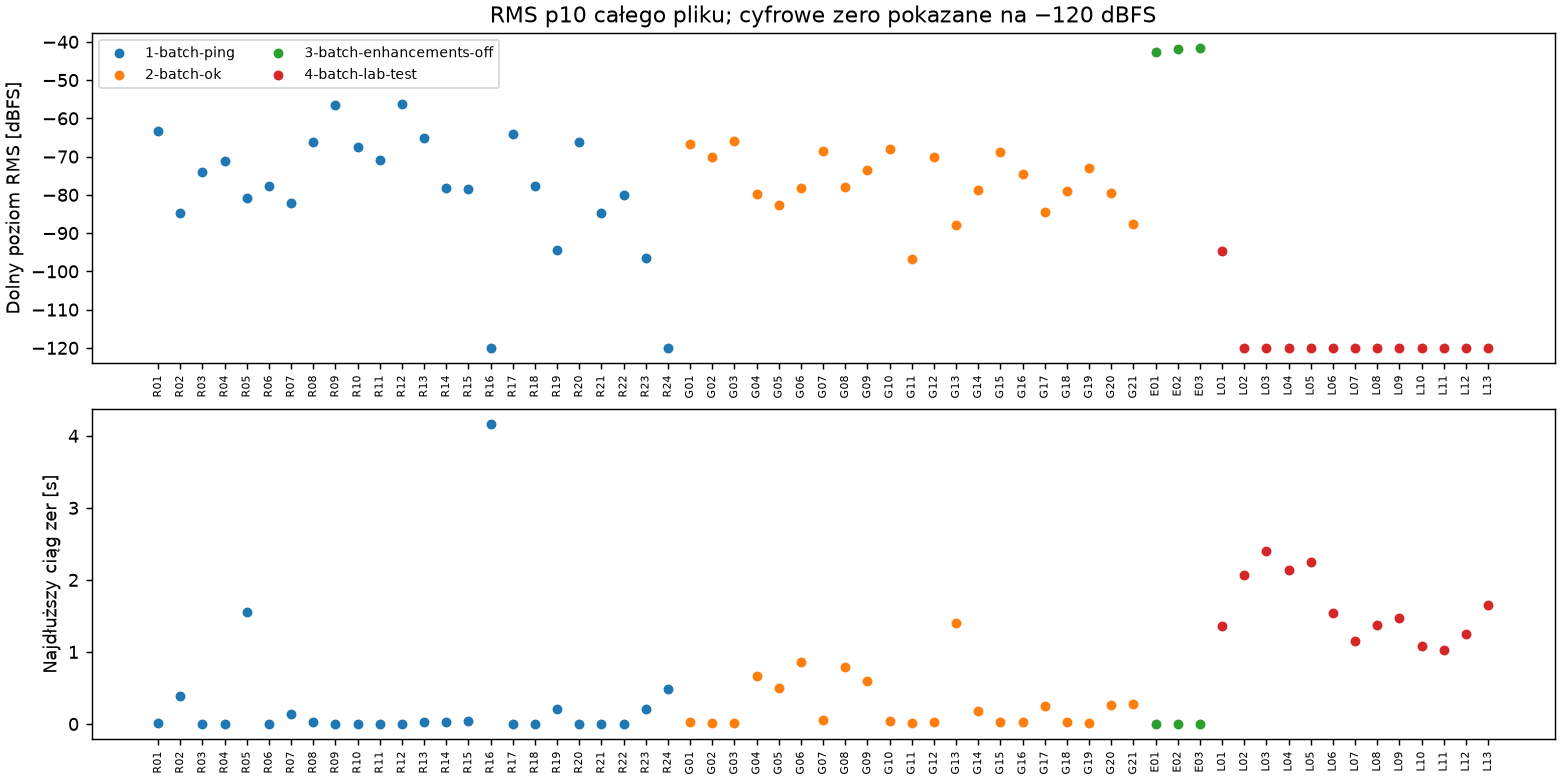

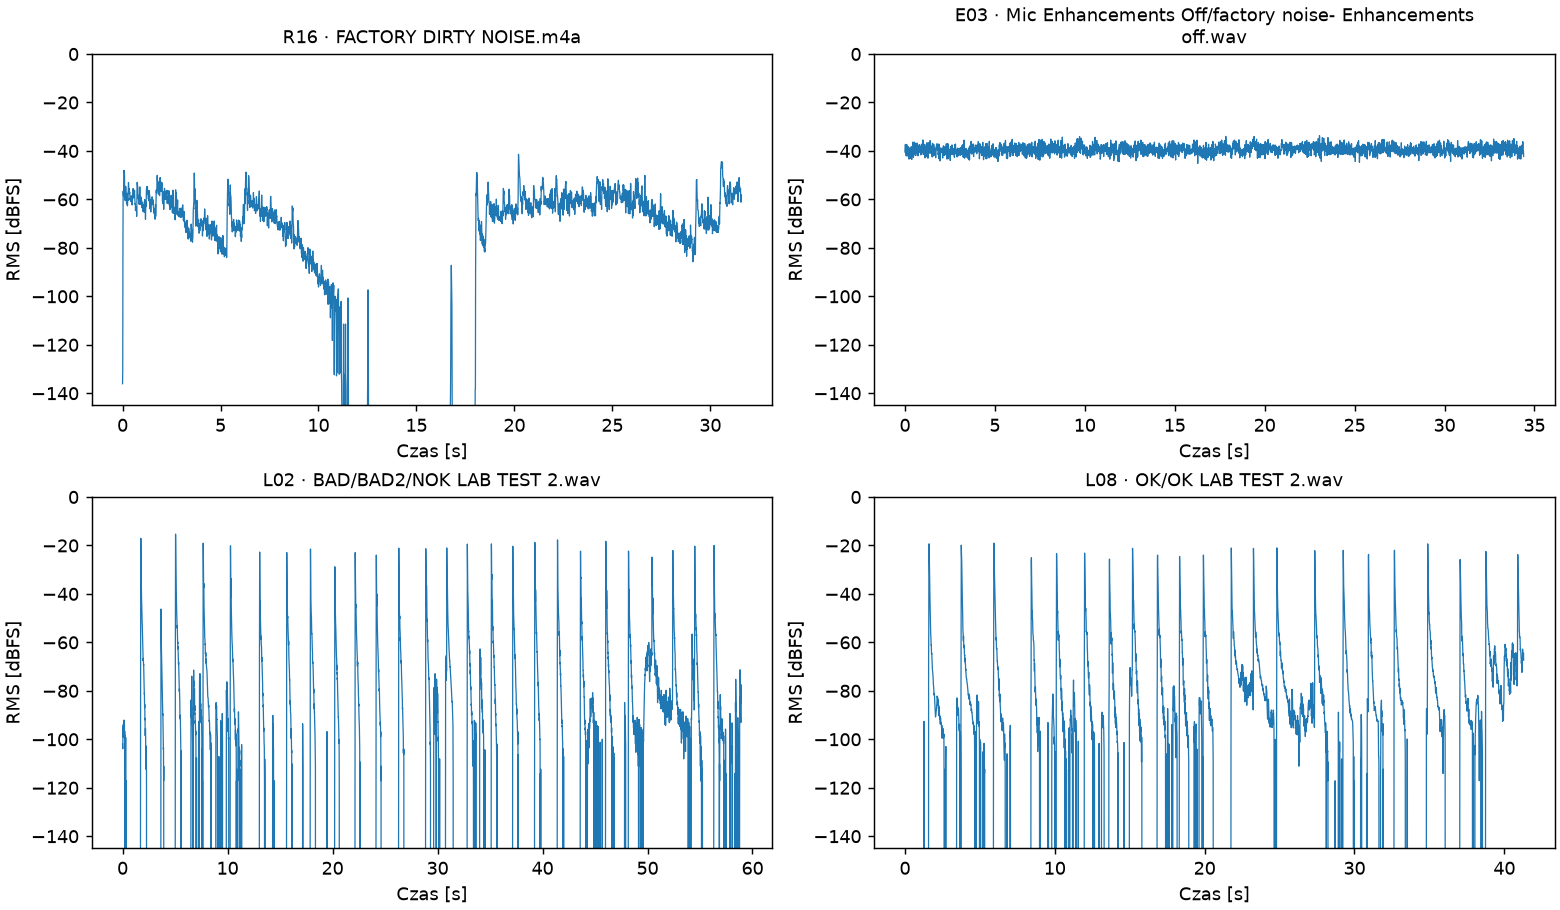

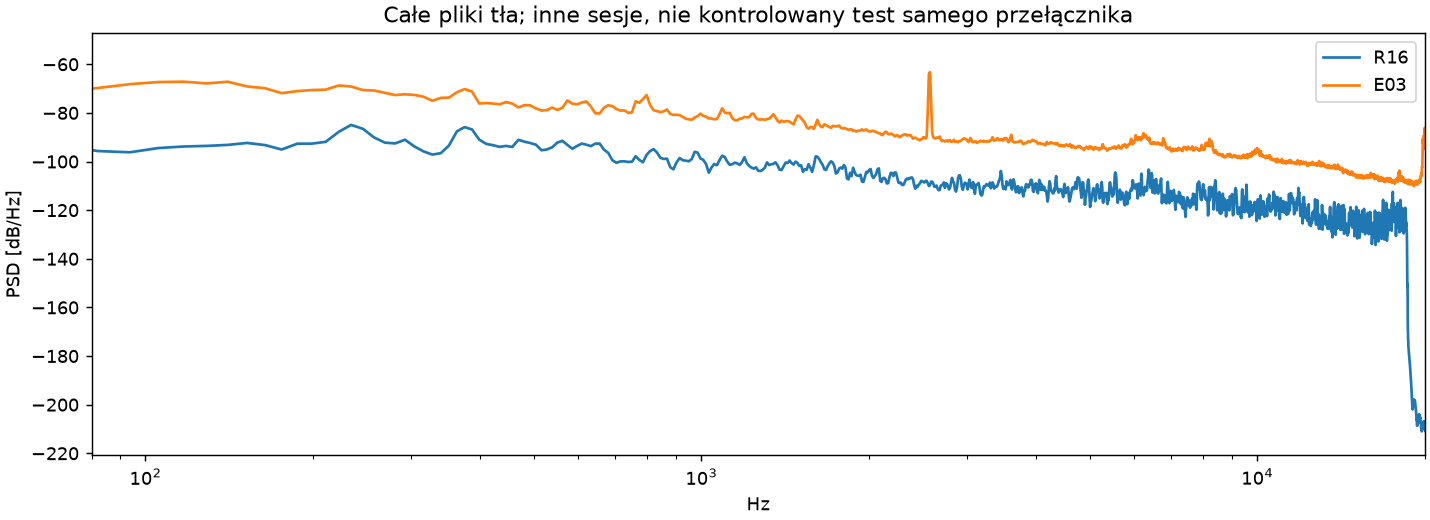

In [19]:
update.figures(ROOT)
display(pd.read_csv(OUT/'batch_quality.csv').round(3))
display(Image(filename=str(OUT/'figures/quality.png')))
display(Image(filename=str(OUT/'figures/envelopes.png')))
display(Image(filename=str(OUT/'figures/background.png')))

## 3. Posłuchaj i sprawdź segmentację
Ustaw RECORDING_ID, START_S i DURATION_S w poniższej komórce i uruchom ją. Odtwarzacz działa bez dodatkowych widgetów JavaScript. Zielone pasy to stałe okna cech, złote linie — odrzucone wykrycia. Odstęp uderzeń jest dłuższy, ale okno modelu pozostaje 170 ms, żeby zachować porównanie z poprzednią rundą. Odsłuch ma oryginalny poziom, bez automatycznego pogłaśniania.

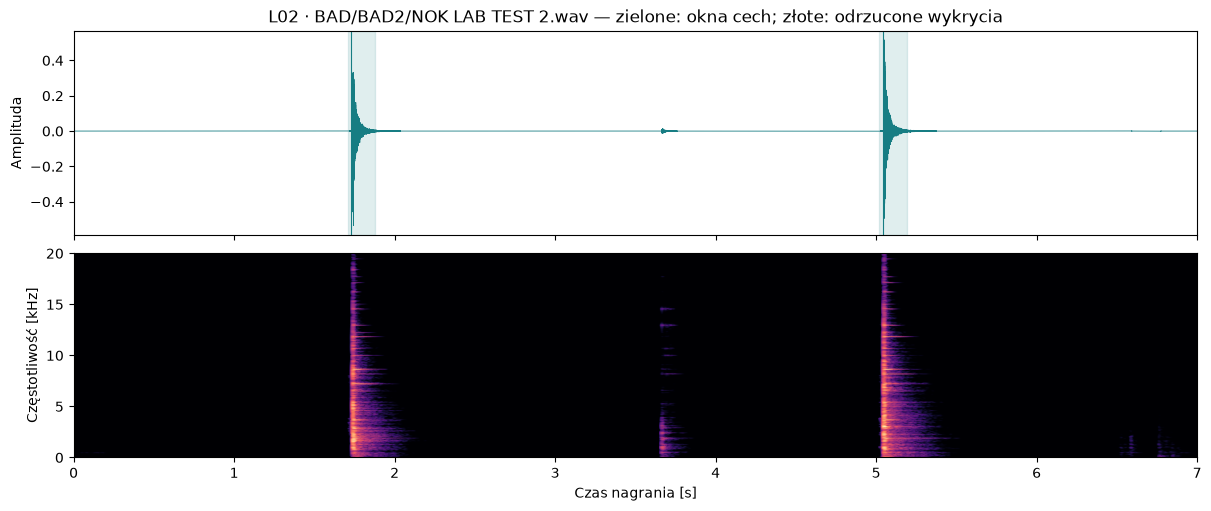

,event_id,onset_s,accepted,rejection
0,L02_001,1.73,True,NaN
1,L02_002,5.04,True,NaN


In [20]:
RECORDING_ID = "L02"  # E01–E03 lub L01–L13; wybierz z tabeli powyżej
START_S = 0
DURATION_S = 7
clientstudy.inspect_recording(RECORDING_ID, START_S, DURATION_S, ROOT, out_rel=update.OUT_REL)

## 4. Uczenie i reprezentacja
Analizujemy wszystkie 61 plików w kontroli jakości. Model pęknięć obejmuje 42 nagrania z roboczymi etykietami OK/NOK; tło, OLD o nieznanej tożsamości i Bitten są poza głównym treningiem. To nie oznacza, że wyszczerbienie jest niewykrywalne — jest innym rodzajem defektu.

Detektor szuka nagłych wzrostów krótkookresowego RMS: ramka 10 ms, krok 5 ms, próg zależny od tła, minimalny odstęp 120 ms. Odrzuca zbyt słabe i niepełne okna. W nowych danych przyjął 258 uderzeń; nie traktujemy ich jako ręcznie potwierdzonych trafień. Model dostaje do 10 równomiernie wybranych uderzeń z nagrania: każde to 20 ms przed + 150 ms po początku, z normalizacją amplitudy. Decyzja o nagraniu to mediana wyników uderzeń, próg 0,5.

Porównujemy physics (15 cech), MFCC (26), ich połączenie (41), zamrożony AST (768). LR: C=0,1. XGBoost: 60 drzew, głębokość 2, bez strojenia na nowych danych. Skalowanie i model uczą się tylko na części treningowej. Kontrola QC używa jedynie poziomu, udziału ciszy i długości pliku, bez widma i kodeka.

W teście łączonym odkładamy całe grupy uznane w danym scenariuszu za płytki: jedną NOK i jedną OK. Dla powtarzających się odłożeń uśredniamy wynik nagrania. Są to wyniki eksploracyjne, zależne od niepotwierdzonych ID; wiele nagrań tej samej sztuki nie jest wieloma niezależnymi płytkami. Scenariusze nie wyczerpują wszystkich możliwych przypisań. Nowe OK roboczo łączymy z OK_1, ale klient może wskazać inne ID.

In [21]:
representations = update.representations(ROOT)
old_to_new, combined = update.model(ROOT)
display(representations.groupby(['batch','scope']).agg(uderzenia=('event_id','size'),nagrania=('recording_id','nunique')))
print('Żaden model nie jest strojony na nowej dostawie; warianty i próg są ustalone.')

AST: 1/148


AST: 26/148
AST: 51/148
AST: 76/148
AST: 101/148
AST: 126/148
Evaluated identity scenario: same_BAD2
Evaluated identity scenario: new_BAD2_merge_old
Evaluated identity scenario: new_BAD2_only_old_Bad1
Evaluated identity scenario: new_BAD2_only_old_Bad2


uderzenia  nagrania
batch                    scope                           
1-batch-ping             chipped             60         6
                         core                90         9
                         old_unknown         80         8
2-batch-ok               core               180        18
3-batch-enhancements-off core                20         2
4-batch-lab-test         core               128        13

Żaden model nie jest strojony na nowej dostawie; warianty i próg są ustalone.


## 5. Czy stary model radzi sobie z nową dostawą?
Trening: tylko poprzednie 27 nagrań głównych. Test: 15 nowych; nowe tło nie ma etykiety OK/NOK. To rozdział po dostawie, nie potwierdzony test nowych fizycznych płytek. tp/fn = wykryte/przeoczone NOK, tn/fp = przyjęte/odrzucone OK.

In [22]:
cols = ['model','n','accuracy','balanced_accuracy','recall_nok','tp','fn','tn','fp','auc']
display(old_to_new[cols].round(3))
display(pd.read_csv(OUT/'old_to_new_by_batch.csv')[['model','batch','n','tp','fn','tn','fp','auc']].round(3))
display(Markdown('**Oba OK z Enhancements Off są odrzucane przez modele akustyczne.** Nie mamy NOK z tej samej paczki. NaN w metrykach jednej klasy oznacza brak możliwości oceny, nie wynik zero.'))

,model,n,accuracy,balanced_accuracy,recall_nok,tp,fn,tn,fp,auc
0,physics + LR,15,0.467,0.500,1.000,7,0,0,8,0.071
1,physics + XGB,15,0.467,0.500,1.000,7,0,0,8,0.179
2,MFCC + LR,15,0.800,0.812,1.000,7,0,5,3,0.964
3,MFCC + XGB,15,0.733,0.750,1.000,7,0,4,4,0.964
4,MFCC + physics + LR,15,0.600,0.625,1.000,7,0,2,6,0.821
5,MFCC + physics + XGB,15,0.533,0.562,1.000,7,0,1,7,0.946
6,AST + LR,15,0.667,0.670,0.714,5,2,5,3,0.554
7,AST + XGB,15,0.533,0.536,0.571,4,3,4,4,0.500
8,QC no codec + LR,15,0.533,0.500,0.000,0,7,8,0,0.268


,model,batch,n,tp,fn,tn,fp,auc
0,AST + LR,3-batch-enhancements-off,2,0,0,0,2,NaN
1,AST + LR,4-batch-lab-test,13,5,2,5,1,0.738
2,AST + XGB,3-batch-enhancements-off,2,0,0,0,2,NaN
3,AST + XGB,4-batch-lab-test,13,4,3,4,2,0.667
4,MFCC + LR,3-batch-enhancements-off,2,0,0,0,2,NaN
5,MFCC + LR,4-batch-lab-test,13,7,0,5,1,1.000
6,MFCC + XGB,3-batch-enhancements-off,2,0,0,0,2,NaN
7,MFCC + XGB,4-batch-lab-test,13,7,0,4,2,1.000
8,MFCC + physics + LR,3-batch-enhancements-off,2,0,0,0,2,NaN
9,MFCC + physics + LR,4-batch-lab-test,13,7,0,2,4,1.000


**Oba OK z Enhancements Off są odrzucane przez modele akustyczne.** Nie mamy NOK z tej samej paczki. NaN w metrykach jednej klasy oznacza brak możliwości oceny, nie wynik zero.

## 6. Modele na połączonych danych — cztery założenia o ID
Nie wybieramy najkorzystniejszego scenariusza. Klient powinien wskazać właściwe przypisanie; jeśli jest inne, przeliczamy podział. Zmiana scenariusza potrafi też zmienić zestaw ocenianych plików, więc zakres wyników nie jest przedziałem ufności.

In [23]:
display(Markdown('\n'.join(f'- **{key}**: {value}' for key,value in update.SCENARIOS.items())))
r = combined[combined.level.eq('recording')]
display(r.pivot(index='model',columns='scenario',values='balanced_accuracy').round(3))
display(r[['scenario',*cols]].round(3))
# Pełne definicje train/test: identity_scenarios.json; wyniki każdego odłożenia: folds_*.csv.

- **same_BAD2**: Nowe BAD2 = stare Bad_2; nowe OK = OK_1. Stare Bad_1 pozostaje osobną płytką.
- **new_BAD2_merge_old**: Nowe BAD2 jest nowe; stare Bad_1 i Bad_2 traktujemy jako jedną sztukę. Nowe OK = OK_1.
- **new_BAD2_only_old_Bad1**: Nowe BAD2 jest nowe; tylko stare Bad_1 jest pewną klasą NOK. Stare Bad_2 wyłączone. Nowe OK = OK_1.
- **new_BAD2_only_old_Bad2**: Nowe BAD2 jest nowe; tylko stare Bad_2 jest pewną klasą NOK. Stare Bad_1 wyłączone. Nowe OK = OK_1.

scenario,new_BAD2_merge_old,new_BAD2_only_old_Bad1,new_BAD2_only_old_Bad2,same_BAD2
model,,,,
AST + LR,0.385,0.385,0.346,0.654
AST + XGB,0.346,0.346,0.346,0.584
MFCC + LR,0.837,0.871,0.878,0.962
MFCC + XGB,0.748,0.748,0.782,0.834
MFCC + physics + LR,0.798,0.851,0.840,0.942
MFCC + physics + XGB,0.709,0.710,0.782,0.815
QC no codec + LR,0.531,0.545,0.500,0.688
always OK,0.500,0.500,0.500,0.500
physics + LR,0.594,0.614,0.545,0.656


,scenario,model,n,accuracy,balanced_accuracy,recall_nok,tp,fn,tn,fp,auc
0,same_BAD2,AST + LR,42,0.690,0.654,0.500,8,8,21,5,0.668
1,same_BAD2,AST + XGB,42,0.619,0.584,0.438,7,9,19,7,0.673
2,same_BAD2,MFCC + LR,42,0.952,0.962,1.000,16,0,24,2,0.976
3,same_BAD2,MFCC + XGB,42,0.810,0.834,0.938,15,1,19,7,0.899
4,same_BAD2,MFCC + physics + LR,42,0.929,0.942,1.000,16,0,23,3,0.923
5,same_BAD2,MFCC + physics + XGB,42,0.786,0.815,0.938,15,1,18,8,0.899
6,same_BAD2,QC no codec + LR,42,0.762,0.688,0.375,6,10,26,0,0.505
7,same_BAD2,physics + LR,42,0.619,0.656,0.812,13,3,13,13,0.577
8,same_BAD2,physics + XGB,42,0.714,0.745,0.875,14,2,16,10,0.656
9,same_BAD2,always OK,42,0.619,0.500,0.000,0,16,26,0,0.500


## 7. Co dalej
Najwięcej wniesie para OK/NOK w jednym ustawieniu z ulepszeniami off i potwierdzonymi ID. Kilka uderzeń co około 2 s, WAV bez obróbki, kilka sekund tła. Nie potrzeba teraz rozbudowanego formularza. Bitten i OLD zachowujemy do osobnego przeglądu; ich wynik nie mierzy skuteczności wykrywania pęknięć.

In [24]:
display(pd.read_csv(OUT/'excluded_diagnostic_predictions.csv').round(3))
build_report()
display(Markdown(QUESTIONS))
print('Raport:', OUT/'START.html')
print('Nowe oryginały:', ROOT/'assets/3-batch-enhancements-off', ROOT/'assets/4-batch-lab-test')

,recording_id,group,label,score,model
0,R10,Bad_3_Bitten,1,0.801,MFCC + LR
1,R11,Bad_3_Bitten,1,0.037,MFCC + LR
2,R12,Bad_3_Bitten,1,0.111,MFCC + LR
3,R13,Bad_4_Bitten,1,0.124,MFCC + LR
4,R14,Bad_4_Bitten,1,0.038,MFCC + LR
5,R15,Bad_4_Bitten,1,0.014,MFCC + LR
6,R17,NaN,1,0.815,MFCC + LR
7,R18,NaN,1,0.942,MFCC + LR
8,R19,NaN,1,0.879,MFCC + LR
9,R20,NaN,0,0.054,MFCC + LR


1. Czy nowe `BAD/BAD2` to ta sama fizyczna płytka co wcześniejsze `Bad_2`, czy nowa pęknięta sztuka? Prosimy o krótkie przypisanie: folder → ID płytki → pęknięcie / wyszczerbienie / OK.
2. Czy pliki w `LAB TEST` powstały przed czy po wyłączeniu ulepszeń? Czy `LAB` oznacza inne pomieszczenie, aplikację lub mikrofon? W każdym z tych 13 plików nadal są długie odcinki dokładnego zera.
3. Czy `OK` z LAB i `OK` z Mic Enhancements Off to ta sama płytka? Która z poprzednich OK? Czy końcówki 2 i 3 oznaczają powtórzenie nagrania, a nie nową sztukę?
4. Co oznacza `angle` (kąt mikrofonu czy uderzenia) oraz `single point / one point` (miejsce uderzania czy podparcie)? W tych ZIP-ach nie znaleźliśmy nazw `no freq` ani `no frequency`.

Raport: /Users/karolsii/dev/ceramic-ping-lab/reports/runs/client-update-20260930/START.html
Nowe oryginały: /Users/karolsii/dev/ceramic-ping-lab/assets/3-batch-enhancements-off /Users/karolsii/dev/ceramic-ping-lab/assets/4-batch-lab-test
